# CLARA: shared-completion certificates

Executed inspection of the frozen TCGA and separate MSK data. This notebook accepts typed specifications; it is not a language-parser evaluation. Full registries can be rebuilt offline with `python reproducibility/run_all.py`. Main paper: unmodified IEEE two-column conference format.

In [1]:
from pathlib import Path
import sys,json,hashlib,subprocess
import numpy as np,pandas as pd
ROOT=Path.cwd()
assert (ROOT/'reproducibility').is_dir()
sys.path.insert(0,str(ROOT/'reproducibility'))
from engine import load_snapshot,PROTOCOL,Spec
from analyze import verify_snapshot
from completion import CompletionModel,GraphPlanner,product_prior
from verify_completion_lp import verify_model,cache_stats
verify_snapshot()
for entry in json.loads((ROOT/'data/msk/manifest.json').read_text())['files']:
    p=ROOT/entry['local_path']
    assert hashlib.sha256(p.read_bytes()).hexdigest()==entry['sha256']
    assert p.stat().st_size==entry['bytes']
print('Frozen TCGA and commit-pinned MSK input hashes verified.')

Frozen TCGA and commit-pinned MSK input hashes verified.


In [2]:
samples,mutations=load_snapshot()
summ=json.loads((ROOT/'completion_results/summary.json').read_text())
msk=json.loads((ROOT/'msk_results/summary.json').read_text())
print('TCGA:',len(samples),'specimens;',samples.groupby('cohort').patient.nunique().sum(),'patients')
print('MSK:',msk['samples'],'specimens;',msk['patients'],'patients;',msk['patients_with_repeated_specimens'],'repeated-specimen patients')
print('SQL/pandas matching specifications:',summ['interpretations']+msk['interpretations'])
print('TCGA sensitivity:',summ['families_sensitive'])
print('Box-only pair alarms:',summ['box_only_pair_count'],'; beyond equivalence:',summ['merged_box_only_pair_count'])

TCGA: 6210 specimens; 6204 patients
MSK: 10945 specimens; 10336 patients; 562 repeated-specimen patients
SQL/pandas matching specifications: 6240
TCGA sensitivity: {'observed': 323, 'coupled': 356, 'box': 356, 'box_merged': 356}
Box-only pair alarms: 3048 ; beyond equivalence: 289


## Shared specimen states yield sharp paired bounds

Missing broad/restricted statuses are nested and shared across every interpretation. The patient OR stays inside each patient block; global support is the sum of local supports.

In [3]:
model=CompletionModel(samples,mutations,'kirc','VHL')
A,_=model.absolute_certificate()
Rlo,Rhi=model.relative_certificate()
print('Unknown specimens:',model.unprofiled_samples,'; largest unknown patient block:',model.max_unprofiled_per_patient)
print('KIRC VHL broad cohort interval:',model.lower[4],model.upper[4])
print('Patient vs specimen broad cohort sharp discrepancy (pp):',A[4,12])
BA,BR=model.independent_interval_certificate()
print('Independent-box discrepancy (pp):',BA[4,12])
print('Broad vs restricted cohort sharp absolute:',A[4,5],'pp; relative bracket:',Rlo[4,5],Rhi[4,5])
witness,indices=model.support_witness(4,5)
print('Attaining absolute-support witness fractions:',witness[[4,5]])
assert abs(100*(witness[4]-witness[5])-A[4,5])<1e-10

Unknown specimens: 110 ; largest unknown patient block: 1
KIRC VHL broad cohort interval: 0.32421875 0.5390625
Patient vs specimen broad cohort sharp discrepancy (pp): 0.0
Independent-box discrepancy (pp): 21.484375
Broad vs restricted cohort sharp absolute: 33.3984375 pp; relative bracket: 0.8976377952731127 0.8976377952749317
Attaining absolute-support witness fractions: [0.5390625  0.20507812]


In [4]:
ov=CompletionModel(samples,mutations,'ov','BRCA1')
OA,_=ov.absolute_certificate();OBA,_=ov.independent_interval_certificate()
print('OV BRCA1, all vs primary cohort: sharp',OA[4,6],'pp; box',OBA[4,6],'pp')
assert OA[4,6]>0 and not ov.certificate_graph()[4,6]
assert ov.independent_interval_graph(merge_equivalent=True)[4,6]
print('This alarm persists in the box baseline after exact equivalence merging.')

OV BRCA1, all vs primary cohort: sharp 0.04691325446042427 pp; box 10.645203852751022 pp
This alarm persists in the box baseline after exact equivalence merging.


In [5]:
policy=GraphPlanner(model.certificate_graph())
print('KIRC VHL uniform expected cost:',policy.solve(policy.root)[0])
weighted=GraphPlanner(model.certificate_graph(),product_prior([.8,.2,.5,.8]),costs=(1,3,3,1))
print('Stipulated prior/cost example: expected optimum',weighted.solve(weighted.root)[0],'; minimax',weighted.solve(weighted.root,'minimax')[0])
print(pd.read_csv(ROOT/'completion_results/uniform_planning_summary.csv')[['certificate','exact_expected','best_global_fixed','best_family_fixed']].to_string(index=False))
print('Per-family fixed ordering matches the primary sharp optimum. Scenarios are not user-study outcomes.')

KIRC VHL uniform expected cost: 2.0
Stipulated prior/cost example: expected optimum 4.0 ; minimax 4.0
certificate  exact_expected  best_global_fixed  best_family_fixed
   observed        1.148611           1.238194           1.148611
    coupled        1.773264           1.830208           1.773264
        box        2.496875           2.553819           2.497569
 box_merged        1.833333           1.890278           1.834028
Per-family fixed ordering matches the primary sharp optimum. Scenarios are not user-study outcomes.


In [6]:
from audit_query import make_audit
card=make_audit('kirc','VHL',{'assay_denominator':'cohort','sample_context':'all','mutation_scope':'broad'})
print('Status:',card['status'])
print('Semantic stable:',card['semantic_certificate']['stable'],'; further questions:',card['uniform_prior_expected_questions'])
print('Interval:',card['answer']['interval'],'; minimax point radius (pp):',card['identification_guard']['minimax_point_radius_pp'])
assert card['status']=='interval_answer' and card['answer']['minimax_point'] is None
print('Clarifying meaning does not collect missing assays.')

Status: interval_answer
Semantic stable: True ; further questions: 0.0
Interval: [0.32421875, 0.5390625] ; minimax point radius (pp): 10.7421875
Clarifying meaning does not collect missing assays.


In [7]:
pairs_checked=verify_model(model,samples,mutations)
print('Independently constructed global LP pair checks in KIRC VHL:',pairs_checked)
print(cache_stats())
for name in ['test_engine.py','test_completion.py']:
    r=subprocess.run([sys.executable,str(ROOT/'reproducibility'/name)],cwd=ROOT,capture_output=True,text=True)
    print(r.stdout+r.stderr)
    assert r.returncode==0
print('All 34 contracts pass. General repeated-unknown logic is additionally verified by the 64 fixtures in the full analysis.')

Independently constructed global LP pair checks in KIRC VHL: 120
{'distinct_global_lp_objectives': 15, 'reused_global_lp_objectives': 465, 'method': 'Global HiGHS LP with nested-class constraints; exact integer support comparisons'}
test_empty_denominator_is_undefined (__main__.CountingContracts.test_empty_denominator_is_undefined) ... ok
test_invalid_enum_fails (__main__.CountingContracts.test_invalid_enum_fails) ... ok
test_missingness_bound (__main__.CountingContracts.test_missingness_bound) ... ok
test_patient_union_and_duplicate_deduplication (__main__.CountingContracts.test_patient_union_and_duplicate_deduplication) ... ok
test_primary_context_does_not_inherit_metastatic_mutation (__main__.CountingContracts.test_primary_context_does_not_inherit_metastatic_mutation) ... ok
test_sample_unit (__main__.CountingContracts.test_sample_unit) ... ok
test_truncating_scope_and_silent_exclusion (__main__.CountingContracts.test_truncating_scope_and_silent_exclusion) ... ok
test_unprofiled_pos

## Central matrix

Computed sharp absolute diameters over all shared completions, with 33 observed-stable families becoming completion-sensitive. Sensitivity also uses the relative criterion, so color alone does not classify a family. The figure is an original vector/data rendering, not image synthesis.

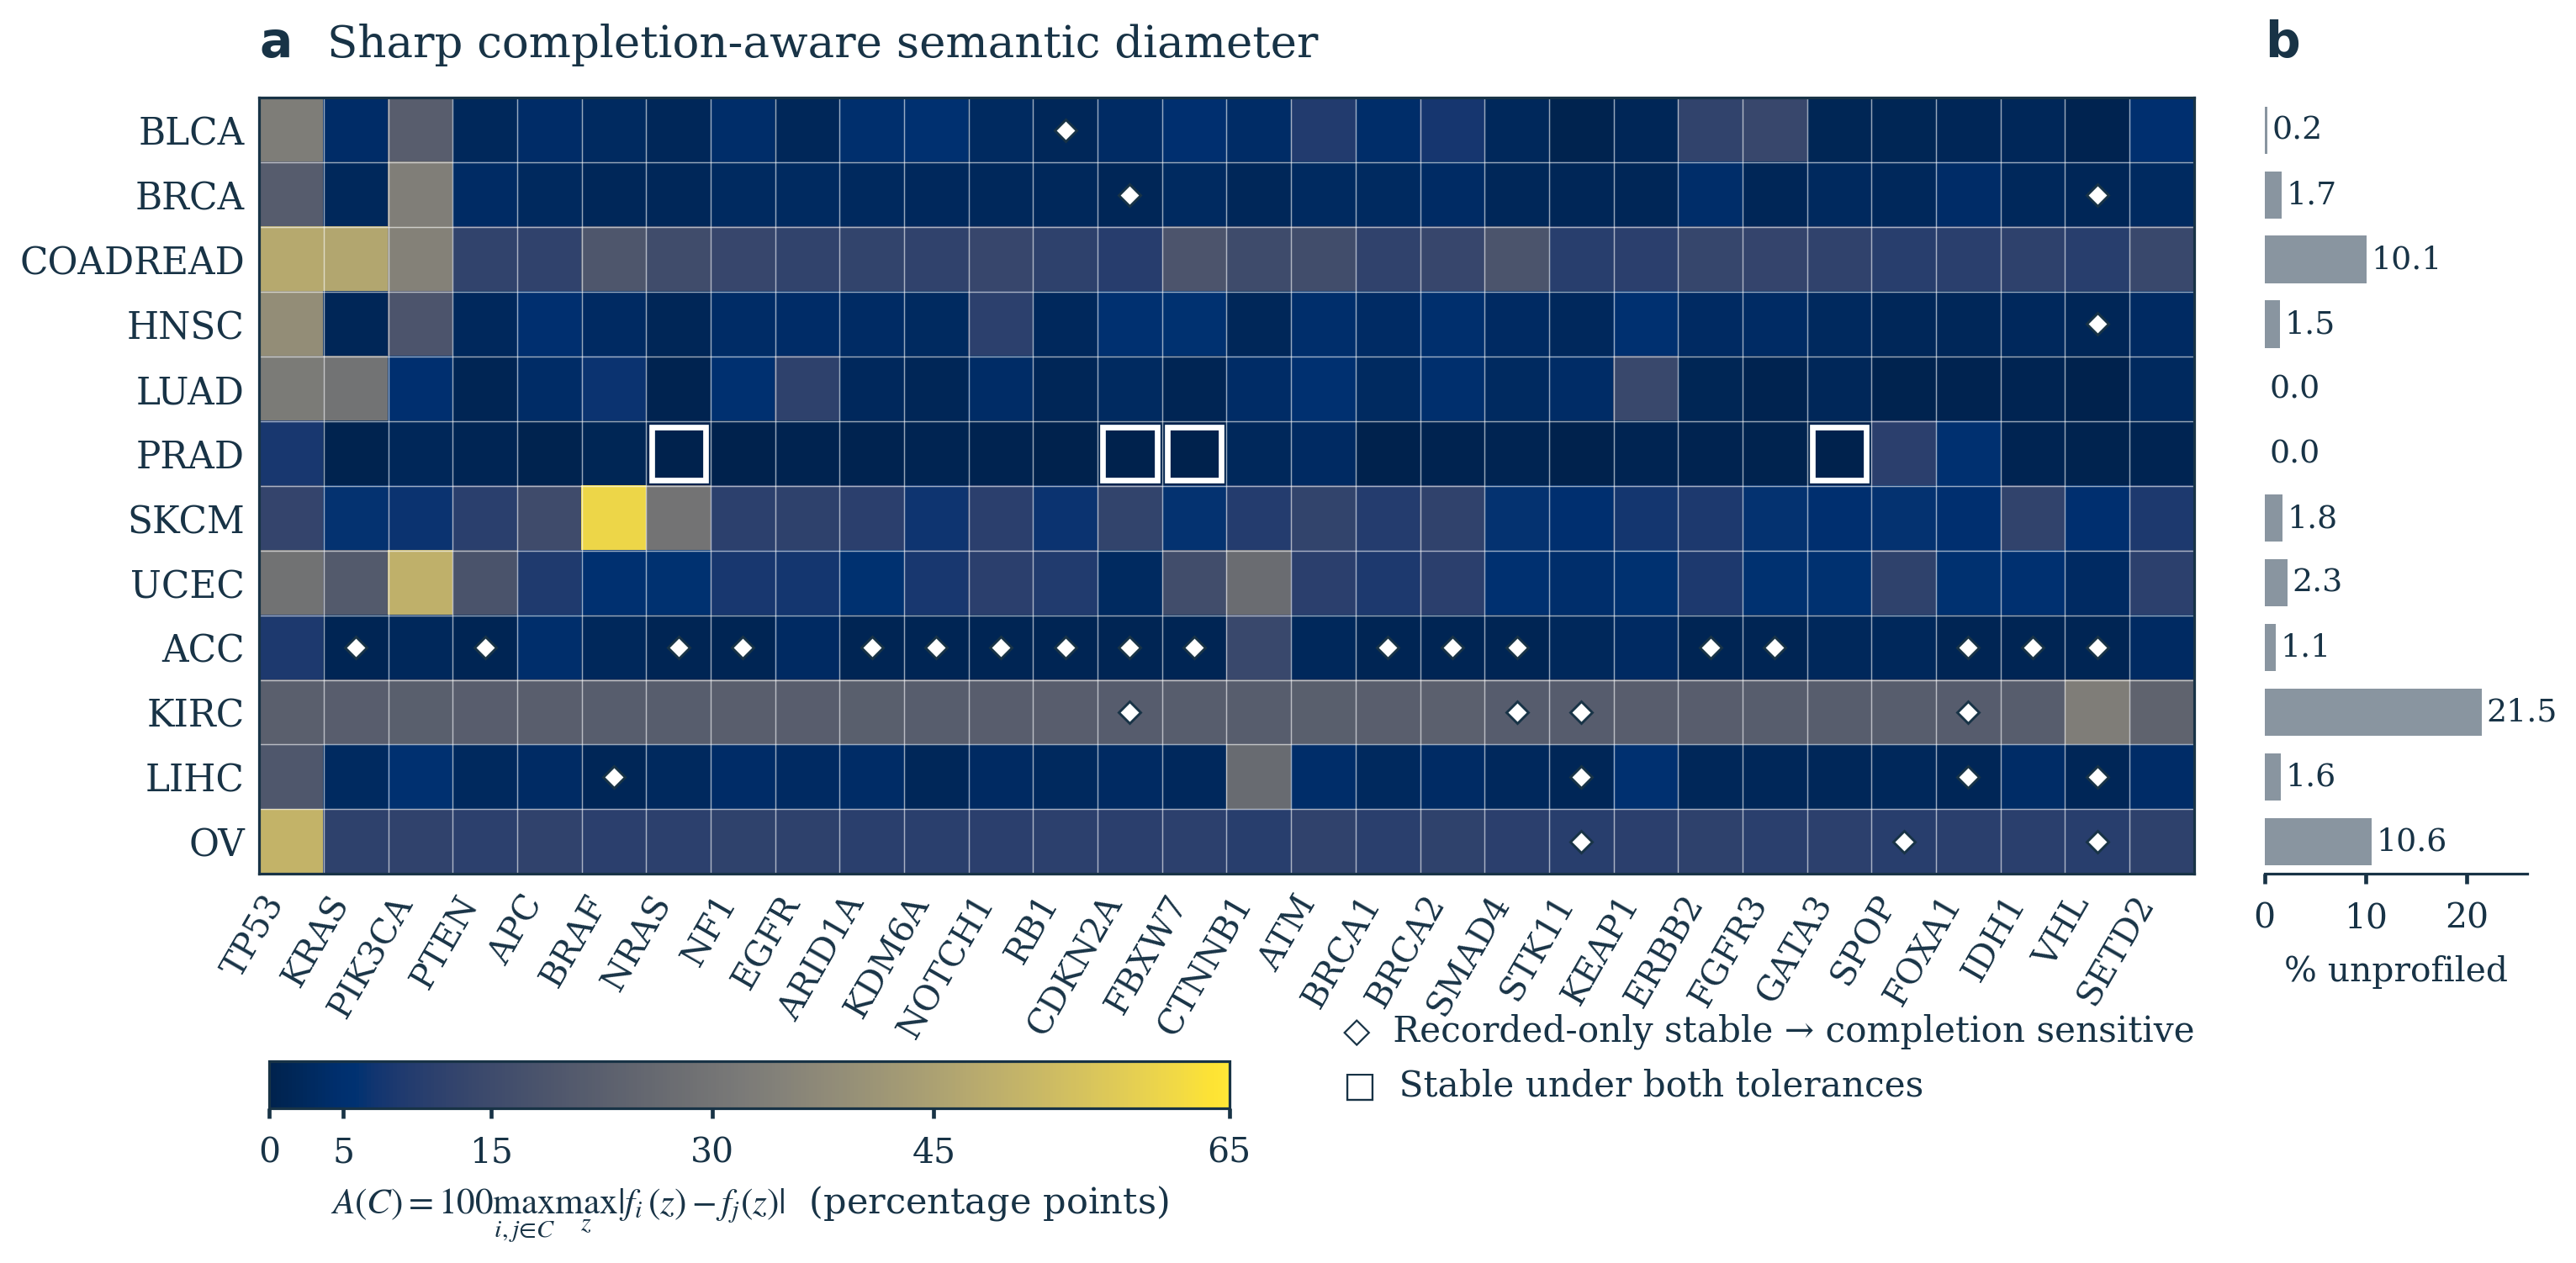

In [8]:
from PIL import Image
Image.open(ROOT/'figures_next/02_matrix.png')

## Typed guard and measured serial scalability

The caller supplies supported fields. This executes a provenance-bound guard, without invoking a language model. Timings describe prepared-table work and labeled synthetic workloads.

In [9]:
from guard_demo import guard,verify
receipt=guard({'cohort':'kirc','gene':'VHL','fields':{'assay_denominator':'cohort','sample_context':'all','mutation_scope':'broad'}})
assert verify(receipt,replay=True)
print('Replayed guard:',receipt['certificate']['status'])
print('Snapshot content binding:',receipt['bindings']['snapshot_content_sha256'])
print('Point suppressed:',receipt['certificate']['answer']['minimax_point'] is None)
r=subprocess.run([sys.executable,str(ROOT/'reproducibility/test_guard.py')],cwd=ROOT,capture_output=True,text=True)
print(r.stdout+r.stderr)
assert r.returncode==0
print('43 total software contracts: 16 counting, 18 completion/planning, 9 typed guard.')

Replayed guard: interval_answer
Snapshot content binding: 7313b56b5662e478ba3626b6d0cf9c2904273380d09d9681441259ffe0cf19dd
Point suppressed: True
test_full_replay (__main__.GuardContracts.test_full_replay) ... ok
test_identified_profiled_fraction (__main__.GuardContracts.test_identified_profiled_fraction) ... ok
test_interval_instead_of_unidentified_point (__main__.GuardContracts.test_interval_instead_of_unidentified_point) ... ok
test_missing_fields_require_clarification (__main__.GuardContracts.test_missing_fields_require_clarification) ... ok
test_modified_answer_rejected (__main__.GuardContracts.test_modified_answer_rejected) ... ok
test_modified_binding_rejected (__main__.GuardContracts.test_modified_binding_rejected) ... ok
test_nonfinite_budget_rejected (__main__.GuardContracts.test_nonfinite_budget_rejected) ... ok
test_unsupported_field_value_rejected (__main__.GuardContracts.test_unsupported_field_value_rejected) ... ok
test_unsupported_fields_rejected (__main__.GuardContract

In [10]:
scale=json.loads((ROOT/'scale_results/summary.json').read_text())
print('Serial workers:',scale['workers'],'; CPU:',scale['cpu'])
print('Model preparation seconds:',scale['model_construction_total_ms']/1000)
print(pd.read_csv(ROOT/'scale_results/registry_scaling.csv')[['axis','cohorts','genes','families','median_ms','min_ms','max_ms']].sort_values(['axis','families']).to_string(index=False))
print('Synthetic workloads are not new patient cohorts; local repeated-unprofiled states still grow exponentially.')
constraints=json.loads((ROOT/'scale_results/constraint_sensitivity.json').read_text())
print('KIRC unknown patients to measure for guaranteed 2.5 pp radius:',constraints['additional_unknown_patients_to_measure_for_guaranteed_2_5pp_radius'])

Serial workers: 1 ; CPU: AMD EPYC 9V74 80-Core Processor
Model preparation seconds: 20.561005198
   axis  cohorts  genes  families   median_ms      min_ms      max_ms
cohorts        1     30        30   89.144048   86.321307   97.242977
cohorts        3     30        90  326.318445  302.369113  370.381391
cohorts        6     30       180  555.731122  498.188233  591.232830
cohorts       12     30       360 1039.535880 1008.680166 1175.252963
  genes       12      1        12   35.801172   34.469818   36.734403
  genes       12      5        60  185.013408  181.852496  188.550618
  genes       12     10       120  372.430283  347.995250  444.302107
  genes       12     20       240  711.675291  668.641351  714.628507
  genes       12     30       360 1098.589117 1005.411660 1246.026015
Synthetic workloads are not new patient cohorts; local repeated-unprofiled states still grow exponentially.
KIRC unknown patients to measure for guaranteed 2.5 pp radius: 85
